In [1]:
import os
import pandas as pd
from datetime import datetime
import pydicom
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import csv
import re
from venn import venn


from utils.selection import *


# Source of RAW DICOMs
BERN_PATH='/nasdata/Berner_Daten/Other_Side_Bilddaten' 
# Project data path
ANALYSIS_PATH='/home/bule/berner_daten_analyse/data'

In [2]:
dwi_tags_df=pd.read_csv(os.path.join(ANALYSIS_PATH,'dwi_through_tags.csv'))
dwi_tags_df

,Patient_ID,Study_ID,Sequence_ID,File_Name,Full_Path,Date,Sequence_ID_split
0,12219800,20141003_3468260,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,28.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/001...,2014-10-03,ep2d_diff_M128_b0_1000_DIN
1,12219800,20141003_3468260,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,1.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/001...,2014-10-03,ep2d_diff_M128_b0_1000_DIN
2,12219800,20141003_3468260,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,10.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/001...,2014-10-03,ep2d_diff_M128_b0_1000_DIN
3,12219800,20141003_3468260,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,11.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/001...,2014-10-03,ep2d_diff_M128_b0_1000_DIN
4,12219800,20141003_3468260,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,12.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/001...,2014-10-03,ep2d_diff_M128_b0_1000_DIN
...,...,...,...,...,...,...,...
34290,82789223,20160522_4001736,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,50.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-05-22,ep2d_diff_M128_b0_1000_DIN
34291,82789223,20160522_4001736,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,6.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-05-22,ep2d_diff_M128_b0_1000_DIN
34292,82789223,20160522_4001736,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,7.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-05-22,ep2d_diff_M128_b0_1000_DIN
34293,82789223,20160522_4001736,ep2d_diff_M128_b0_1000_DIN__1.3.12.2.1107.5.2....,8.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-05-22,ep2d_diff_M128_b0_1000_DIN


In [3]:
t1_df=pd.read_csv(os.path.join(ANALYSIS_PATH,'t1_df.csv'))
t1_df

,Patient_ID,Study_ID,Sequence_ID,File_Name,Full_Path,Date,Sequence_ID_split,Sequence_ID_split_selection,HB_JD_HB_selection
0,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,1.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/000...,2017-09-29,t1_se_tra,True,1.0
1,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,10.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/000...,2017-09-29,t1_se_tra,True,1.0
2,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,11.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/000...,2017-09-29,t1_se_tra,True,1.0
3,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,12.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/000...,2017-09-29,t1_se_tra,True,1.0
4,76813,20170929_4371316,t1_se_tra__1.3.12.2.1107.5.2.41.169589.2017092...,13.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/000...,2017-09-29,t1_se_tra,True,1.0
...,...,...,...,...,...,...,...,...,...
18949,82789223,20161003_4120929,t1_fl2d_tra_3mm__1.3.12.2.1107.5.2.43.67081.20...,5.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-10-03,t1_fl2d_tra_3mm,True,1.0
18950,82789223,20161003_4120929,t1_fl2d_tra_3mm__1.3.12.2.1107.5.2.43.67081.20...,6.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-10-03,t1_fl2d_tra_3mm,True,1.0
18951,82789223,20161003_4120929,t1_fl2d_tra_3mm__1.3.12.2.1107.5.2.43.67081.20...,7.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-10-03,t1_fl2d_tra_3mm,True,1.0
18952,82789223,20161003_4120929,t1_fl2d_tra_3mm__1.3.12.2.1107.5.2.43.67081.20...,8.dcm,/nasdata/Berner_Daten/Other_Side_Bilddaten/008...,2016-10-03,t1_fl2d_tra_3mm,True,1.0


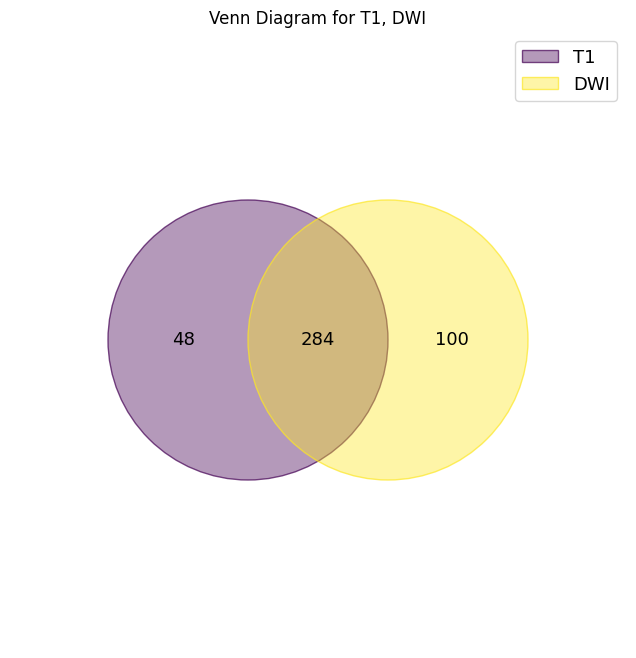

In [4]:
data = {
    'T1': set(t1_df['Patient_ID']),
    'DWI': set(dwi_tags_df['Patient_ID'])
}
set_labels = {
    'T1': data['T1'],

    'DWI': data['DWI']
}
venn(set_labels)
plt.title("Venn Diagram for T1, DWI")
plt.show()

- merge the table

In [ ]:
t1_df_sel=t1_df[['Patient_ID', 'Study_ID', 'Sequence_ID', 'File_Name', 'Full_Path', 'Date', 'Sequence_ID_split']]
t1_df_sel['Modality']='T1'
dwi_tags_df['Modality']='DWI'

dwi_t1_df_2 = pd.concat([dwi_tags_df, t1_df_sel],ignore_index=True)

dwi_t1_df_2.to_csv(os.path.join(ANALYSIS_PATH,'dwi_t1_df_2.csv'), index=False)

In [29]:
df_path = "/home/bule/berner_daten_analyse/data/dwi_t1_df_2.csv" #
df = pd.read_csv(df_path)

In [ ]:
df